In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df = df[["v1", "v2"]].copy()

df.columns = ["label", "message"]

df = df.dropna(subset=["label", "message"]).reset_index(drop=True)

df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Cleaned dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
print("Label distribution:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


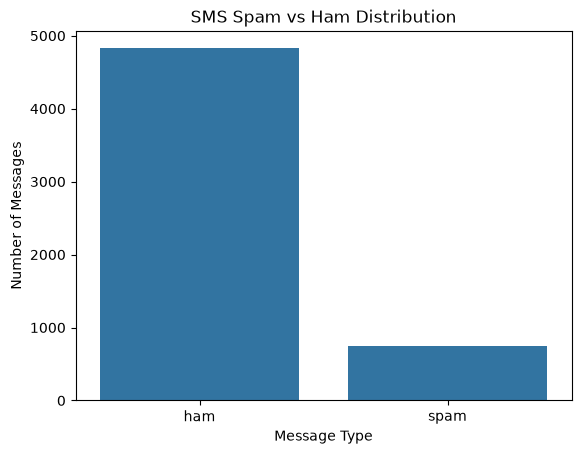

In [5]:
sns.countplot(data=df, x="label")
plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [6]:
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "target"]].head())
print("\nTarget distribution:")
print(df["target"].value_counts())

  label  target
0   ham       0
1   ham       0
2  spam       1
3   ham       0
4   ham       0

Target distribution:
target
0    4825
1     747
Name: count, dtype: int64


In [7]:
df["message_length"] = df["message"].str.len()

df["num_digits"] = df["message"].apply(
    lambda text: sum(char.isdigit() for char in text)
)

df["num_capitals"] = df["message"].apply(
    lambda text: sum(char.isupper() for char in text)
)

display(
    df[[
        "message",
        "message_length",
        "num_digits",
        "num_capitals",
        "label"
    ]].head(10)
)

,message,message_length,num_digits,num_capitals,label
0,"Go until jurong point, crazy.. Available only ...",111,0,3,ham
1,Ok lar... Joking wif u oni...,29,0,2,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,25,10,spam
3,U dun say so early hor... U c already then say...,49,0,2,ham
4,"Nah I don't think he goes to usf, he lives aro...",61,0,2,ham
5,FreeMsg Hey there darling it's been 3 week's n...,148,4,7,spam
6,Even my brother is not like to speak with me. ...,77,0,2,ham
7,As per your request 'Melle Melle (Oru Minnamin...,160,1,10,ham
8,WINNER!! As a valued network customer you have...,158,19,12,spam
9,Had your mobile 11 months or more? U R entitle...,154,13,14,spam


In [8]:
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

assert df["target"].notna().all(), "Unexpected label values found!"

df["target"] = df["target"].astype(int)

print(df[["label", "target"]].head())
print("\nTarget distribution:")
print(df["target"].value_counts())

  label  target
0   ham       0
1   ham       0
2  spam       1
3   ham       0
4   ham       0

Target distribution:
target
0    4825
1     747
Name: count, dtype: int64


In [9]:
X = df["message"]
y = df["target"]

# 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Divide the remaining 40% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nSplit percentages:")
print(f"Training:   {len(X_train) / len(df) * 100:.2f}%")
print(f"Validation: {len(X_val) / len(df) * 100:.2f}%")
print(f"Testing:    {len(X_test) / len(df) * 100:.2f}%")

Training samples: 3343
Validation samples: 1114
Testing samples: 1115

Split percentages:
Training:   60.00%
Validation: 19.99%
Testing:    20.01%


In [10]:
tfidf = TfidfVectorizer(max_features=1000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nNumber of vocabulary features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (3343, 1000)
Validation TF-IDF shape: (1114, 1000)
Testing TF-IDF shape: (1115, 1000)

Number of vocabulary features: 1000


In [11]:
numeric_cols = [
    "message_length",
    "num_digits",
    "num_capitals"
]

train_numeric = df.loc[X_train.index, numeric_cols].to_numpy()
val_numeric = df.loc[X_val.index, numeric_cols].to_numpy()
test_numeric = df.loc[X_test.index, numeric_cols].to_numpy()

print("Training numerical shape:", train_numeric.shape)
print("Validation numerical shape:", val_numeric.shape)
print("Testing numerical shape:", test_numeric.shape)

Training numerical shape: (3343, 3)
Validation numerical shape: (1114, 3)
Testing numerical shape: (1115, 3)


In [12]:
scaler = StandardScaler()

train_numeric_scaled = scaler.fit_transform(train_numeric)
val_numeric_scaled = scaler.transform(val_numeric)
test_numeric_scaled = scaler.transform(test_numeric)

print("Numerical features scaled successfully.")

Numerical features scaled successfully.


In [13]:
X_train_final = hstack([
    X_train_tfidf,
    csr_matrix(train_numeric_scaled)
]).tocsr()

X_val_final = hstack([
    X_val_tfidf,
    csr_matrix(val_numeric_scaled)
]).tocsr()

X_test_final = hstack([
    X_test_tfidf,
    csr_matrix(test_numeric_scaled)
]).tocsr()

print("Final training matrix:", X_train_final.shape)
print("Final validation matrix:", X_val_final.shape)
print("Final testing matrix:", X_test_final.shape)

assert X_train_final.shape[1] == 1003
assert X_val_final.shape[1] == 1003
assert X_test_final.shape[1] == 1003

print("\nFeature engineering completed successfully!")

Final training matrix: (3343, 1003)
Final validation matrix: (1114, 1003)
Final testing matrix: (1115, 1003)

Feature engineering completed successfully!


In [14]:
C_values = [0.01, 0.1, 1, 10, 100]

tuning_results = []

for c in C_values:
    model = LinearSVC(
        C=c,
        random_state=RANDOM_STATE,
        max_iter=10000
    )

    model.fit(X_train_final, y_train)

    val_pred = model.predict(X_val_final)

    tuning_results.append({
        "C": c,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

best_C = tuning_df.loc[
    tuning_df["F1-score"].idxmax(), "C"
]

print("Best C value:", best_C)

,C,Accuracy,Precision,Recall,F1-score
0,0.01,0.9713,0.9466,0.8322,0.8857
1,0.10,0.9776,0.9627,0.8658,0.9117
2,1.00,0.9847,0.9648,0.9195,0.9416
3,10.00,0.9838,0.9517,0.9262,0.9388
4,100.00,0.9794,0.9200,0.9262,0.9231


Best C value: 1.0


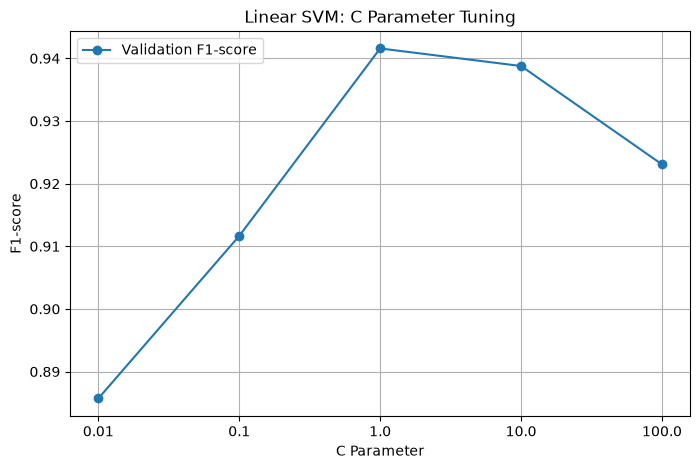

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuning_df["C"].astype(str),
    tuning_df["F1-score"],
    marker="o",
    label="Validation F1-score"
)

plt.xlabel("C Parameter")
plt.ylabel("F1-score")
plt.title("Linear SVM: C Parameter Tuning")
plt.grid(True)
plt.legend()
plt.show()

In [16]:
best_model = LinearSVC(
    C=best_C,
    random_state=RANDOM_STATE,
    max_iter=10000
)

best_model.fit(X_train_final, y_train)

print("Final Linear SVM trained.")
print("Selected C:", best_C)

Final Linear SVM trained.
Selected C: 1.0


In [17]:
y_test_pred = best_model.predict(X_test_final)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, zero_division=0)
recall = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)

print("FINAL TEST METRICS")
print("-" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    digits=4,
    zero_division=0
))

FINAL TEST METRICS
----------------------------------------
Accuracy : 0.9964
Precision: 0.9867
Recall   : 0.9867
F1-score : 0.9867

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9979    0.9979    0.9979       965
        Spam     0.9867    0.9867    0.9867       150

    accuracy                         0.9964      1115
   macro avg     0.9923    0.9923    0.9923      1115
weighted avg     0.9964    0.9964    0.9964      1115



Confusion Matrix:
[[963   2]
 [  2 148]]


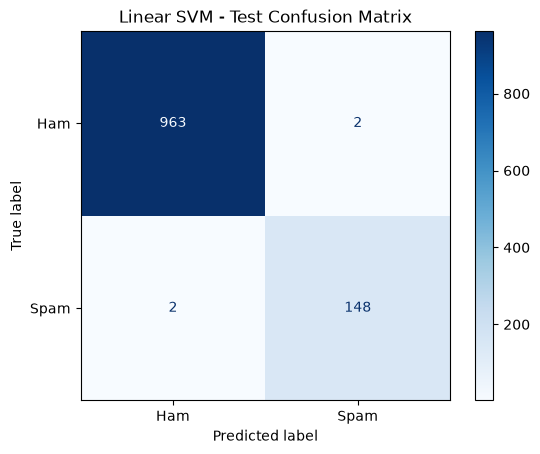

In [18]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Linear SVM - Test Confusion Matrix")
plt.show()

In [19]:
error_analysis = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": y_test_pred
})

error_analysis["actual_label"] = error_analysis["actual"].map({
    0: "Ham",
    1: "Spam"
})

error_analysis["predicted_label"] = error_analysis["predicted"].map({
    0: "Ham",
    1: "Spam"
})

# Add decision scores: positive means predicted spam
error_analysis["decision_score"] = best_model.decision_function(
    X_test_final
)

false_positives = error_analysis[
    (error_analysis["actual"] == 0) &
    (error_analysis["predicted"] == 1)
].copy()

false_negatives = error_analysis[
    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 0)
].copy()

print("Total false positives:", len(false_positives))
print("Total false negatives:", len(false_negatives))

Total false positives: 2
Total false negatives: 2


In [20]:
print("FIVE FALSE POSITIVES")

display(
    false_positives[
        ["message", "actual_label", "predicted_label", "decision_score"]
    ].head(5).reset_index(drop=True)
)

FIVE FALSE POSITIVES


,message,actual_label,predicted_label,decision_score
0,My tuition is at 330. Hm we go for the 1120 to...,Ham,Spam,0.202112
1,K.. I yan jiu liao... Sat we can go 4 bugis vi...,Ham,Spam,0.235505


In [21]:
print("FIVE FALSE NEGATIVES")

display(
    false_negatives[
        ["message", "actual_label", "predicted_label", "decision_score"]
    ].head(5).reset_index(drop=True)
)

FIVE FALSE NEGATIVES


,message,actual_label,predicted_label,decision_score
0,PRIVATE! Your 2003 Account Statement for 078,Spam,Ham,-0.110337
1,Oh my god! I've found your number again! I'm s...,Spam,Ham,-0.668334


In [22]:
fp_report = false_positives.head(5).copy()
fp_report["error_type"] = "False Positive"

fn_report = false_negatives.head(5).copy()
fn_report["error_type"] = "False Negative"

error_report = pd.concat(
    [fp_report, fn_report],
    axis=0
)

error_report = error_report[
    [
        "error_type",
        "message",
        "actual_label",
        "predicted_label",
        "decision_score"
    ]
].reset_index(drop=True)

display(error_report)

,error_type,message,actual_label,predicted_label,decision_score
0,False Positive,My tuition is at 330. Hm we go for the 1120 to...,Ham,Spam,0.202112
1,False Positive,K.. I yan jiu liao... Sat we can go 4 bugis vi...,Ham,Spam,0.235505
2,False Negative,PRIVATE! Your 2003 Account Statement for 078,Spam,Ham,-0.110337
3,False Negative,Oh my god! I've found your number again! I'm s...,Spam,Ham,-0.668334


In [23]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

In [24]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

print("C values:", param_grid["C"])
print("Gamma values:", param_grid["gamma"])
print("Parameter combinations:", 
      len(param_grid["C"]) * len(param_grid["gamma"]))
print("Total CV fits:", 
      len(param_grid["C"]) * len(param_grid["gamma"]) * 5)

C values: [0.1, 1, 10, 100]
Gamma values: [0.001, 0.01, 0.1, 1]
Parameter combinations: 16
Total CV fits: 80


In [25]:
rbf_svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=rbf_svm,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

In [26]:
grid_search.fit(X_train_final, y_train)

print("Grid search completed!")
print("Best parameters:", grid_search.best_params_)
print("Best mean CV F1-score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Grid search completed!
Best parameters: {'C': 100, 'gamma': 0.01}
Best mean CV F1-score: 0.9657


In [27]:
cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = cv_results[
    [
        "param_C",
        "param_gamma",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
    ]
].copy()

results_table = results_table.rename(columns={
    "param_C": "C",
    "param_gamma": "Gamma",
    "mean_test_score": "Mean CV F1",
    "std_test_score": "CV F1 Std",
    "mean_train_score": "Mean Train F1",
    "rank_test_score": "Rank"
})

results_table = results_table.sort_values("Rank")

display(results_table.round(4))

,C,Gamma,Mean CV F1,CV F1 Std,Mean Train F1,Rank
13,100.0,0.010,0.9657,0.0064,0.9907,1
14,100.0,0.100,0.9657,0.0121,1.0000,2
10,10.0,0.100,0.9597,0.0122,0.9938,3
11,10.0,1.000,0.9276,0.0211,1.0000,4
15,100.0,1.000,0.9276,0.0211,1.0000,4
7,1.0,1.000,0.9239,0.0228,0.9838,6
9,10.0,0.010,0.9210,0.0184,0.9358,7
6,1.0,0.100,0.9146,0.0187,0.9265,8
12,100.0,0.001,0.9138,0.0231,0.9314,9
5,1.0,0.010,0.8657,0.0266,0.8690,10


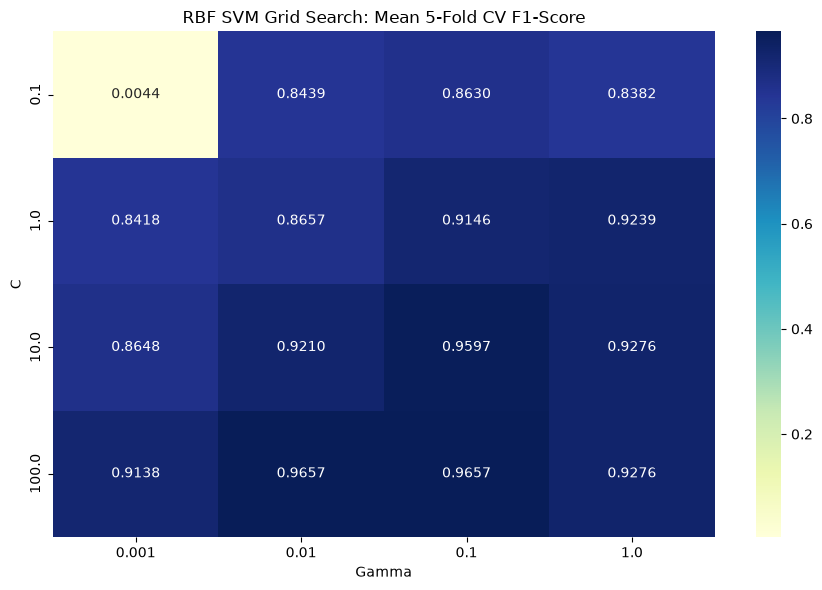

In [28]:
heatmap_data = pd.DataFrame(grid_search.cv_results_)

heatmap_data["C"] = heatmap_data["param_C"].astype(float)
heatmap_data["Gamma"] = heatmap_data["param_gamma"].astype(float)

heatmap_pivot = heatmap_data.pivot(
    index="C",
    columns="Gamma",
    values="mean_test_score"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    heatmap_pivot,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("RBF SVM Grid Search: Mean 5-Fold CV F1-Score")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.tight_layout()
plt.show()

In [29]:
best_rbf_model = grid_search.best_estimator_

y_val_rbf_pred = best_rbf_model.predict(X_val_final)

print("BEST RBF SVM — VALIDATION METRICS")
print("-" * 45)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Accuracy : {accuracy_score(y_val, y_val_rbf_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_rbf_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_rbf_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_val, y_val_rbf_pred, zero_division=0):.4f}")

BEST RBF SVM — VALIDATION METRICS
---------------------------------------------
Best parameters: {'C': 100, 'gamma': 0.01}
Accuracy : 0.9874
Precision: 0.9787
Recall   : 0.9262
F1-score : 0.9517


In [30]:
y_test_rbf_pred = best_rbf_model.predict(X_test_final)

print("BEST RBF SVM — TEST METRICS")
print("-" * 45)

print(f"Accuracy : {accuracy_score(y_test, y_test_rbf_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_rbf_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_rbf_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_test_rbf_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_rbf_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    digits=4,
    zero_division=0
))

BEST RBF SVM — TEST METRICS
---------------------------------------------
Accuracy : 0.9982
Precision: 1.0000
Recall   : 0.9867
F1-score : 0.9933

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9979    1.0000    0.9990       965
        Spam     1.0000    0.9867    0.9933       150

    accuracy                         0.9982      1115
   macro avg     0.9990    0.9933    0.9961      1115
weighted avg     0.9982    0.9982    0.9982      1115



RBF SVM Confusion Matrix:
[[965   0]
 [  2 148]]


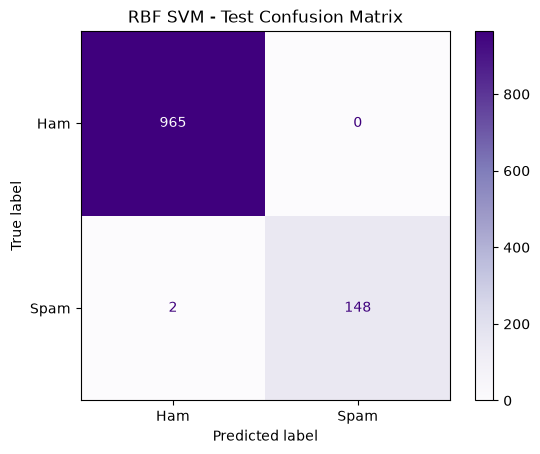

In [31]:
cm_rbf = confusion_matrix(
    y_test,
    y_test_rbf_pred,
    labels=[0, 1]
)

print("RBF SVM Confusion Matrix:")
print(cm_rbf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rbf,
    display_labels=["Ham", "Spam"]
).plot(cmap="Purples", values_format="d")

plt.title("RBF SVM - Test Confusion Matrix")
plt.show()

In [32]:
comparison = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, zero_division=0)
    },
    {
        "Model": "RBF SVM",
        "Accuracy": accuracy_score(y_test, y_test_rbf_pred),
        "Precision": precision_score(y_test, y_test_rbf_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_rbf_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_rbf_pred, zero_division=0)
    }
])

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.9964,0.9867,0.9867,0.9867
1,RBF SVM,0.9982,1.0000,0.9867,0.9933


In [33]:
results_table.to_csv("rbf_svm_grid_search_results.csv", index=False)
comparison.to_csv("svm_model_comparison.csv", index=False)

print("Saved:")
print("- rbf_svm_grid_search_results.csv")
print("- svm_model_comparison.csv")

Saved:
- rbf_svm_grid_search_results.csv
- svm_model_comparison.csv


In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Best Parameters": f"C={best_C}",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, zero_division=0)
    },
    {
        "Model": "RBF SVM",
        "Best Parameters": str(grid_search.best_params_),
        "Accuracy": accuracy_score(y_test, y_test_rbf_pred),
        "Precision": precision_score(y_test, y_test_rbf_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_rbf_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_rbf_pred, zero_division=0)
    }
])

display(comparison.round(4))

,Model,Best Parameters,Accuracy,Precision,Recall,F1-score
0,Linear SVM,C=1.0,0.9964,0.9867,0.9867,0.9867
1,RBF SVM,"{'C': 100, 'gamma': 0.01}",0.9982,1.0000,0.9867,0.9933


In [35]:
# Continuous scores for the positive class (spam = 1)
linear_scores = best_model.decision_function(X_test_final)
rbf_scores = best_rbf_model.decision_function(X_test_final)

linear_auc = roc_auc_score(y_test, linear_scores)
rbf_auc = roc_auc_score(y_test, rbf_scores)

print(f"Linear SVM ROC-AUC: {linear_auc:.4f}")
print(f"RBF SVM ROC-AUC:    {rbf_auc:.4f}")

Linear SVM ROC-AUC: 0.9997
RBF SVM ROC-AUC:    0.9998


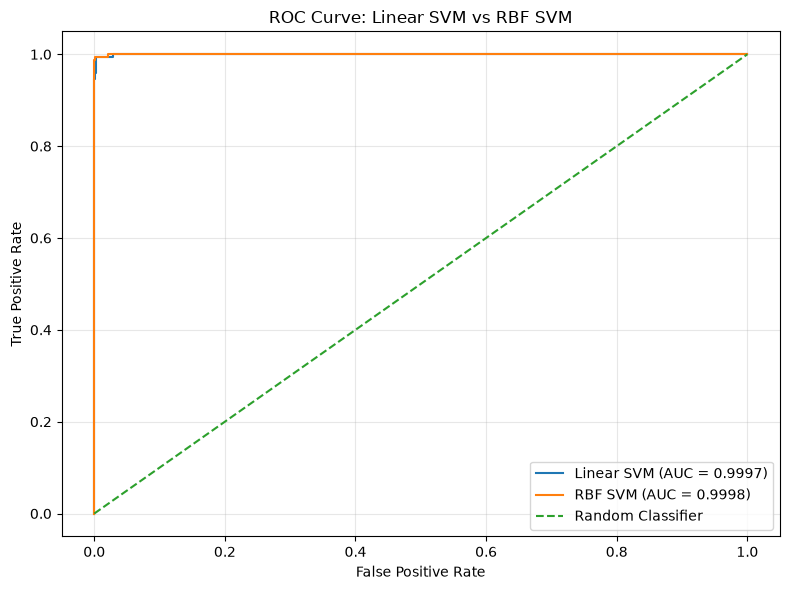

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve points
fpr_linear, tpr_linear, _ = roc_curve(y_test, linear_scores)
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, rbf_scores)

# Plot both curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_linear, tpr_linear,
    label=f"Linear SVM (AUC = {linear_auc:.4f})"
)

plt.plot(
    fpr_rbf, tpr_rbf,
    label=f"RBF SVM (AUC = {rbf_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Linear SVM vs RBF SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
import time

# Linear SVM prediction time
start = time.perf_counter()
_ = best_model.predict(X_test_final)
linear_time = time.perf_counter() - start

# RBF SVM prediction time
start = time.perf_counter()
_ = best_rbf_model.predict(X_test_final)
rbf_time = time.perf_counter() - start

speed_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Prediction Time (seconds)": [linear_time, rbf_time]
})

display(speed_comparison.round(6))

,Model,Prediction Time (seconds)
0,Linear SVM,0.001125
1,RBF SVM,0.059609


In [38]:
final_evaluation = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Best Parameters": f"C={best_C}",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC-AUC": linear_auc,
        "Prediction Time (seconds)": linear_time
    },
    {
        "Model": "RBF SVM",
        "Best Parameters": str(grid_search.best_params_),
        "Accuracy": accuracy_score(y_test, y_test_rbf_pred),
        "Precision": precision_score(y_test, y_test_rbf_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_rbf_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_rbf_pred, zero_division=0),
        "ROC-AUC": rbf_auc,
        "Prediction Time (seconds)": rbf_time
    }
])

display(final_evaluation.round(4))

final_evaluation.to_csv("final_svm_evaluation.csv", index=False)
print("Saved: final_svm_evaluation.csv")

,Model,Best Parameters,Accuracy,Precision,Recall,F1-score,ROC-AUC,Prediction Time (seconds)
0,Linear SVM,C=1.0,0.9964,0.9867,0.9867,0.9867,0.9997,0.0011
1,RBF SVM,"{'C': 100, 'gamma': 0.01}",0.9982,1.0000,0.9867,0.9933,0.9998,0.0596


Saved: final_svm_evaluation.csv


In [39]:
linear_f1 = f1_score(y_test, y_test_pred, zero_division=0)
rbf_f1 = f1_score(y_test, y_test_rbf_pred, zero_division=0)

linear_recall = recall_score(y_test, y_test_pred, zero_division=0)
rbf_recall = recall_score(y_test, y_test_rbf_pred, zero_division=0)

print("PRODUCTION RECOMMENDATION")
print("-" * 35)

if (
    linear_f1 >= rbf_f1 - 0.01
    and linear_recall >= rbf_recall - 0.02
):
    print("Recommend Linear SVM for production.")
    print("It offers competitive spam detection with generally lower")
    print("computational cost and easier interpretation.")
else:
    print("RBF SVM may be worth considering if its improved detection")
    print("performance justifies the additional computational cost.")
    print("Validate latency, memory use, and false-positive rates before deployment.")

print("\nLinear SVM:")
print(f"F1-score: {linear_f1:.4f}")
print(f"Spam recall: {linear_recall:.4f}")
print(f"ROC-AUC: {linear_auc:.4f}")
print(f"Prediction time: {linear_time:.6f} seconds")

print("\nRBF SVM:")
print(f"F1-score: {rbf_f1:.4f}")
print(f"Spam recall: {rbf_recall:.4f}")
print(f"ROC-AUC: {rbf_auc:.4f}")
print(f"Prediction time: {rbf_time:.6f} seconds")

PRODUCTION RECOMMENDATION
-----------------------------------
Recommend Linear SVM for production.
It offers competitive spam detection with generally lower
computational cost and easier interpretation.

Linear SVM:
F1-score: 0.9867
Spam recall: 0.9867
ROC-AUC: 0.9997
Prediction time: 0.001125 seconds

RBF SVM:
F1-score: 0.9933
Spam recall: 0.9867
ROC-AUC: 0.9998
Prediction time: 0.059609 seconds
